<h1 align="center">E-Commerce Customer Segmentation</h1>
<h3 align="center"> Coupons and Electronics Cross-Sell</h3>

**Project:** E-Commerce Customer Segmentation: RFM and K-Means Analysis of Who Drives, and Who Threatens, Revenue

This notebook answers two objectives of the [analysis charter](../02_documentation/analysis_charter.md):

- **Objective 4:** *"Are coupons building loyalty, or subsidising people who would buy anyway?"* (the first project's deferred Q3, discount efficiency)
- **Objective 5:** *"Which customers can help us depend less on Electronics?"*

Notebook 4 found that the loyalty tier, not past behaviour, is the main guide to what a customer does next *[Notebook 4]*. Every comparison of later behaviour here is therefore made **within tier**.

**Steps**

*Part A: Coupons*

1. How the three coupons work, and what they cost by segment and tier.
2. Do coupons raise order value? Each customer's coupon orders are compared with their own non-coupon orders.
3. Is coupon use a lasting customer trait?
4. Do coupon users keep buying? 2026 lapse rate and spend, compared within tier and order count.
5. Percentage against flat coupons: who uses them and where the cost lands.

*Part B: Electronics cross-sell*

6. Electronics dependence groups by segment and tier.
7. Which categories are bought alongside Electronics?
8. Which category do customers actually add?
9. Are Electronics-led customers a bigger risk?
10. Who to target, with which category, and what it could be worth.

**Source tags.** Figures from the first project are tagged *[Report §x]*, and from earlier notebooks *[Notebook 1]*–*[Notebook 4]*. Every other figure is calculated here and is cited elsewhere as *[Notebook 5]*.

| Input | Output |
|---|---|
| `01_data/processed/Fact_Sales.csv`, `Dim_Products.csv` | `01_data/output/coupon_efficiency_by_segment.csv` |
| `01_data/output/customer_features_full.csv`, `customer_features_calibration.csv` *[Notebook 1]* | `01_data/output/cross_sell_targets.csv` |
| `01_data/output/kmeans_segments_full.csv` *[Notebook 3]* | `04_report/figures/Notebook 5_*.png` |
| `01_data/output/holdout_outcomes_calibration.csv` *[Notebook 4]* | |

## Setup

In [1]:
# pathlib: build file paths that work on Windows, macOS and Linux
from pathlib import Path

# pandas: read and reshape the order and customer tables
import pandas as pd

# customer_features.py (this folder): shared order-status rules and time windows
import customer_features as cf

pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

DATA_DIR = Path("../01_data/processed")
OUTPUT_DIR = Path("../01_data/output")
SEGMENT_ORDER = ["Core high-value regulars", "Big-ticket Electronics buyers", "Coupon-led buyers",
                 "Frequent everyday shoppers", "Occasional light shoppers",
                 "Lapsed high-value customers", "Lapsed light buyers"]
TIER_ORDER = ["Silver", "Gold", "Platinum"]

fact, dim_customers, products = cf.load_data(DATA_DIR)
fact["coupon_used"] = fact.coupon_code.notna()

full = pd.read_csv(OUTPUT_DIR / "customer_features_full.csv", index_col="customer_id")
segments_full = pd.read_csv(OUTPUT_DIR / "kmeans_segments_full.csv", index_col="customer_id")
current = full[full.frequency > 0].copy()
current["kmeans_segment"] = pd.Categorical(segments_full.kmeans_segment.reindex(current.index),
                                           categories=SEGMENT_ORDER, ordered=True)
current["customer_tier"] = pd.Categorical(current.customer_tier, categories=TIER_ORDER, ordered=True)

# Valid orders (Delivered, Shipped, Processing) with each customer's current segment and tier
valid = fact[fact.order_status.isin(cf.VALID_STATUSES)].join(
    current[["kmeans_segment", "customer_tier"]], on="customer_id")
print(f"Valid orders: {len(valid):,}; customers: {valid.customer_id.nunique():,}")

Valid orders: 225,000; customers: 39,848


# Part A: Coupons

## 1. How the coupons work and what they cost

The continuity check first reproduces the first project's coupon figures for Jan–Jun 2026, counting every order status as the first project did *[Notebook 1, Section 2]*.

In [2]:
h1_26 = fact[(fact.order_date >= "2026-01-01") & (fact.order_date <= "2026-06-30")]
print(f"Coupon discounts Jan–Jun 2026: ₹{h1_26.coupon_discount.sum() / 1e6:,.1f} M (published ₹14.8 M)")
print(f"Coupon discount rate:          {h1_26.coupon_discount.sum() / h1_26.order_value.sum():.2%} (published 1.04%)")
assert round(h1_26.coupon_discount.sum() / 1e6, 1) == 14.8
assert round(h1_26.coupon_discount.sum() / h1_26.order_value.sum() * 100, 2) == 1.04

coupon_orders = fact[fact.coupon_used].copy()
coupon_orders["discount_share_of_order"] = coupon_orders.coupon_discount / coupon_orders.order_value
mechanics = coupon_orders.groupby("coupon_code").agg(
    orders=("coupon_discount", "size"), min_discount=("coupon_discount", "min"),
    max_discount=("coupon_discount", "max"), mean_discount=("coupon_discount", "mean"),
    mean_share_of_order=("discount_share_of_order", "mean"),
    orders_where_discount_exceeds_value=("discount_share_of_order", lambda s: (s >= 1).sum()))
mechanics.style.format({"orders": "{:,.0f}", "min_discount": "₹{:,.2f}", "max_discount": "₹{:,.0f}",
                        "mean_discount": "₹{:,.0f}", "mean_share_of_order": "{:.1%}",
                        "orders_where_discount_exceeds_value": "{:,.0f}"})

Coupon discounts Jan–Jun 2026: ₹14.8 M (published ₹14.8 M)
Coupon discount rate:          1.04% (published 1.04%)


,orders,min_discount,max_discount,mean_discount,mean_share_of_order,orders_where_discount_exceeds_value
coupon_code,,,,,,
DIWALI100,"12,609",₹100.00,₹100,₹100,6.1%,81
FLAT50,"12,579",₹50.00,₹50,₹50,3.1%,26
SAVE10,"24,997",₹2.61,"₹41,092","₹2,425",10.0%,0


**Findings:**

- **The data reproduces the first project's coupon figures** (₹14.8 M, 1.04% of gross order value in Jan–Jun 2026 *[Report §3.2]*).
- **The three coupons work very differently:**
  - `SAVE10` takes exactly 10% off, so its cost grows with the basket: from ₹2.61 up to **₹41,092 on a single order**, ₹2,425 on average.
  - `FLAT50` and `DIWALI100` always take ₹50 or ₹100.
- **Flat coupons are sometimes worth more than the order.** On 107 orders (81 `DIWALI100`, 26 `FLAT50`), the discount was at least as large as the order value. The money involved is small, but a minimum order value for flat coupons would remove it.

### Coupon cost by segment and tier

All figures use **valid orders over the full 25 months**, so they match the segment revenue in Notebook 3.

- **Coupon rate** = share of the segment's valid orders that used a coupon.
- **Coupon cost rate** = coupon discounts ÷ gross order value (the charter's metric).
- **Discount share of revenue** = coupon discounts ÷ the segment's revenue.

In [3]:
# numpy: array maths for the tables below
import numpy as np


def coupon_cost(by):
    g = valid.groupby(by, observed=True)
    t = g.agg(orders=("order_id", "size"), coupon_orders=("coupon_used", "sum"),
              discount=("coupon_discount", "sum"), gross_order_value=("order_value", "sum"),
              revenue=("total_amount", "sum"))
    t["coupon_rate"] = t.coupon_orders / t.orders
    t["coupon_cost_rate"] = t.discount / t.gross_order_value
    t["discount_share_of_revenue"] = t.discount / t.revenue
    t["share_of_all_discount"] = t.discount / t.discount.sum()
    save10 = valid[valid.coupon_code == "SAVE10"].groupby(by, observed=True).coupon_discount.sum()
    t["save10_share_of_discount"] = save10 / t.discount
    return t[["orders", "coupon_rate", "discount", "share_of_all_discount", "coupon_cost_rate",
              "discount_share_of_revenue", "save10_share_of_discount"]]


COST_FORMAT = {"orders": "{:,.0f}", "coupon_rate": "{:.1%}", "discount": lambda v: f"₹{v / 1e6:,.2f} M",
               "share_of_all_discount": "{:.1%}", "coupon_cost_rate": "{:.2%}",
               "discount_share_of_revenue": "{:.2%}", "save10_share_of_discount": "{:.1%}"}
cost_by_segment = coupon_cost("kmeans_segment")
cost_by_tier = coupon_cost("customer_tier")
print(f"All valid orders: coupon discounts ₹{valid.coupon_discount.sum() / 1e6:,.1f} M, "
      f"{valid.coupon_discount.sum() / valid.order_value.sum():.2%} of gross order value")
display(cost_by_segment.style.format(COST_FORMAT))
display(cost_by_tier.style.format(COST_FORMAT))

All valid orders: coupon discounts ₹56.4 M, 1.05% of gross order value


,orders,coupon_rate,discount,share_of_all_discount,coupon_cost_rate,discount_share_of_revenue,save10_share_of_discount
kmeans_segment,,,,,,,
Core high-value regulars,"78,370",13.2%,₹16.95 M,30.0%,0.71%,0.71%,97.7%
Big-ticket Electronics buyers,"21,087",18.5%,₹8.97 M,15.9%,0.94%,0.95%,98.4%
Coupon-led buyers,"34,373",41.7%,₹19.93 M,35.3%,2.15%,2.20%,97.3%
Frequent everyday shoppers,"46,033",17.9%,₹4.40 M,7.8%,0.97%,0.98%,93.1%
Occasional light shoppers,"27,745",18.7%,₹2.49 M,4.4%,0.98%,0.99%,92.1%
Lapsed high-value customers,"13,267",16.5%,₹3.35 M,5.9%,0.88%,0.89%,97.4%
Lapsed light buyers,"4,125",24.8%,₹0.32 M,0.6%,1.44%,1.46%,88.1%


,orders,coupon_rate,discount,share_of_all_discount,coupon_cost_rate,discount_share_of_revenue,save10_share_of_discount
customer_tier,,,,,,,
Silver,"21,685",20.5%,₹1.45 M,2.6%,1.20%,1.22%,88.5%
Gold,"32,854",20.3%,₹3.63 M,6.4%,1.14%,1.15%,93.2%
Platinum,"170,461",20.0%,₹51.34 M,91.0%,1.04%,1.05%,97.5%


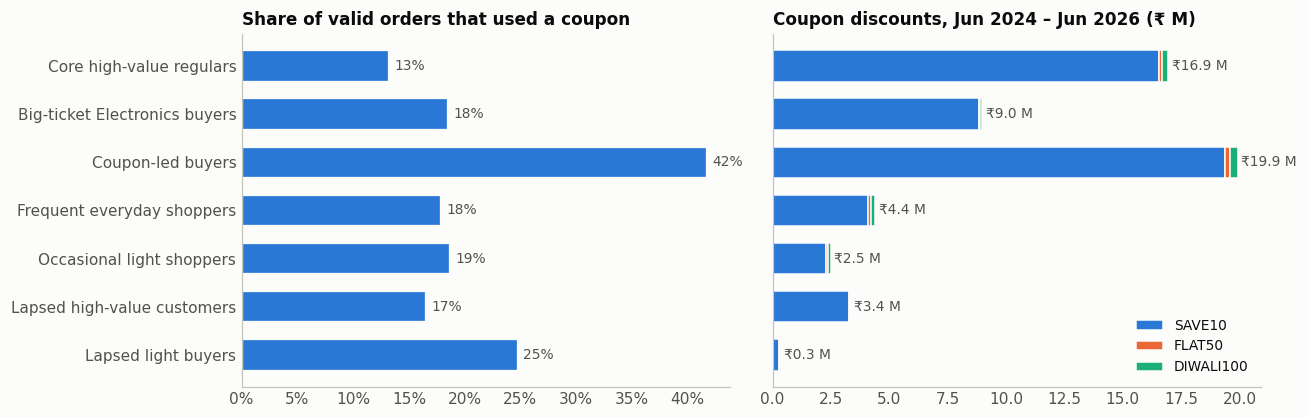

In [ ]:
# matplotlib: draw the charts; FuncFormatter formats axis numbers
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# plot_style.py (this folder): shared colours and chart defaults for every notebook
import plot_style as ps
ps.apply()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.9), sharey=True)
seg = cost_by_segment.index.astype(str)[::-1]

ax = axes[0]
rates = cost_by_segment.coupon_rate[::-1]
ax.barh(seg, rates, height=0.65, **ps.bar_kwargs())
for y, v in enumerate(rates):
    ax.text(v + 0.005, y, f"{v:.0%}", va="center", fontsize=9, color=ps.TEXT_SECONDARY)
ax.set_title("Share of valid orders that used a coupon", fontsize=11)
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:.0%}"))
ax.grid(axis="y", visible=False)

ax = axes[1]
by_code = (valid[valid.coupon_used].pivot_table(index="kmeans_segment", columns="coupon_code", values="coupon_discount",
                                                aggfunc="sum", observed=True)
           .reindex(SEGMENT_ORDER)[["SAVE10", "FLAT50", "DIWALI100"]] / 1e6)[::-1]
left = np.zeros(len(by_code))
for i, codename in enumerate(by_code.columns):
    ax.barh(by_code.index.astype(str), by_code[codename], left=left, height=0.65, color=ps.SERIES[i],
            edgecolor=ps.SURFACE, linewidth=1, label=codename)
    left += by_code[codename].to_numpy()
for y, v in enumerate(left):
    ax.text(v + 0.15, y, f"₹{v:,.1f} M", va="center", fontsize=9, color=ps.TEXT_SECONDARY)
ax.set_title("Coupon discounts, Jun 2024 – Jun 2026 (₹ M)", fontsize=11)
ax.legend(frameon=False, loc="lower right", fontsize=9)
ax.grid(axis="y", visible=False)
fig.tight_layout()
ps.save(fig, "Notebook 5_coupon_cost_by_segment")
plt.show()

**Findings:**

- **Coupons cost ₹56.4 M over the 25 months, 1.05% of gross order value**, in line with the first project's 1.04% for one half-year.
- **`SAVE10` is almost the entire cost:** 88%–98% of discounts in every segment and tier.
- **Coupon-led buyers cost the most.** They are 14.1% of customers *[Notebook 3]* but take 35.3% of all discounts (₹19.93 M), with a coupon on 41.7% of orders and a cost rate of 2.15%.
- **Core high-value regulars are next** (₹16.95 M, 30.0%). They use coupons least (13.2% of orders), but their large baskets make each `SAVE10` expensive.
- **By tier, coupon use is the same** (20.0%–20.5% of orders). Platinum takes 91.0% of the cost because Platinum baskets are bigger.

## 2. Do coupons raise order value?

Notebook 1 compared all coupon orders with all non-coupon orders and found a 1.7% difference *[Notebook 1, Q8]*. That comparison mixes different customers. A fairer test compares **each customer with themselves**: every valid order's gross value (before the discount) is divided by that customer's own average order value. A **relative order value** of 1.10 means the order was 10% larger than that customer's usual order. If coupons raise basket size, coupon orders should have a relative value above 1 on average, and above the customer's non-coupon orders.

This avoids a trap: comparing the *median* of each customer's coupon orders with their other orders would be biased, because most customers have only one or two coupon orders, and a single order from a skewed distribution is usually below that customer's average. Averages of relative order value are not affected by this.

Only customers with at least one coupon and one non-coupon valid order are included. A t-test checks whether the gap between coupon and non-coupon orders is larger than chance.

In [5]:
# scipy ttest_ind: compare the average relative order value of coupon and non-coupon orders
from scipy.stats import ttest_ind

mixed_customers = valid.groupby("customer_id").coupon_used.agg(lambda c: c.any() and not c.all())
within = valid[valid.customer_id.map(mixed_customers)].copy()
within["relative_order_value"] = within.order_value / within.groupby("customer_id").order_value.transform("mean")

coupon_rel = within.loc[within.coupon_used, "relative_order_value"]
other_rel = within.loc[~within.coupon_used, "relative_order_value"]
t_stat, p = ttest_ind(coupon_rel, other_rel, equal_var=False)
print(f"Customers with both coupon and non-coupon orders: {within.customer_id.nunique():,} of {len(current):,}")
print(f"Average relative order value: coupon orders {coupon_rel.mean():.3f}, other orders {other_rel.mean():.3f} "
      f"(gap {coupon_rel.mean() / other_rel.mean() - 1:+.1%}, p = {p:.3f})")


def within_summary(by):
    g = within.groupby([by, "coupon_used"], observed=True).relative_order_value.mean().unstack()
    g.columns = ["other_orders", "coupon_orders"]
    g["gap"] = g.coupon_orders / g.other_orders - 1
    g.insert(0, "customers", within.groupby(by, observed=True).customer_id.nunique())
    g["p_value"] = [ttest_ind(within.loc[(within[by] == k) & within.coupon_used, "relative_order_value"],
                              within.loc[(within[by] == k) & ~within.coupon_used, "relative_order_value"],
                              equal_var=False)[1] for k in g.index]
    return g


WITHIN_FORMAT = {"customers": "{:,.0f}", "other_orders": "{:.3f}", "coupon_orders": "{:.3f}", "gap": "{:+.1%}", "p_value": "{:.3f}"}
within_by_segment = within_summary("kmeans_segment")
display(within_by_segment.style.format(WITHIN_FORMAT))
display(within_summary("customer_tier").style.format(WITHIN_FORMAT))

Customers with both coupon and non-coupon orders: 26,769 of 39,848
Average relative order value: coupon orders 1.011, other orders 0.996 (gap +1.5%, p = 0.027)


,customers,other_orders,coupon_orders,gap,p_value
kmeans_segment,,,,,
Core high-value regulars,"7,380",0.995,1.021,+2.6%,0.055
Big-ticket Electronics buyers,"2,881",1.000,1.000,+0.0%,0.996
Coupon-led buyers,"5,530",0.996,1.006,+1.1%,0.420
Frequent everyday shoppers,"5,021",0.997,1.009,+1.2%,0.469
Occasional light shoppers,"3,617",0.996,1.009,+1.2%,0.449
Lapsed high-value customers,"1,706",0.990,1.025,+3.5%,0.214
Lapsed light buyers,634,1.009,0.988,-2.1%,0.513


,customers,other_orders,coupon_orders,gap,p_value
customer_tier,,,,,
Silver,"2,925",1.003,0.994,-0.8%,0.655
Gold,"4,183",0.994,1.015,+2.1%,0.230
Platinum,"19,661",0.996,1.012,+1.6%,0.037


**Finding: coupon orders are only 1.5% larger than the same customer's other orders.**

- **Overall:** 26,769 customers have both kinds of order. Their coupon orders average 1.011 times their usual order value, against 0.996 for their other orders, a gap of +1.5% (p = 0.027). This matches Notebook 1's +1.7% from the simpler comparison *[Notebook 1, Q8]*.
- **By segment, no gap is clearly different from zero.** Gaps range from −2.1% to +3.5%, and every p-value is above 0.05. Core high-value regulars come closest (+2.6%, p = 0.055).
- **By tier:** Platinum +1.6% (p = 0.037), Gold +2.1% and Silver −0.8% (neither significant).

**Implication:** coupons do not meaningfully enlarge baskets for any segment. A 10% discount bought, at most, about 1.5% of extra order value.

## 3. Is coupon use a lasting customer trait?

A coupon-targeting segment only makes sense if the same customers keep using coupons. Two checks:

1. **More variation than chance?** If every order had the same chance of using a coupon, customers would still differ in coupon rate just by luck, more so for customers with few orders. The spread expected from luck alone (binomial variance) is compared with the spread actually seen. A ratio near 1 means coupon use looks random from order to order.
2. **Does it carry forward?** Each customer's coupon rate in 2024–25 (calibration) is compared with their rate in Jan–Jun 2026, for customers who ordered at least twice in 2026.

In [6]:
# scipy spearmanr: rank correlation, which does not assume a straight-line relationship
from scipy.stats import spearmanr

p_all = fact.coupon_used.mean()
observed_var = full.coupon_rate.var()
expected_var = (p_all * (1 - p_all) / full.orders_placed).mean()
print(f"Share of all orders using a coupon: {p_all:.1%}")
print(f"Variance of customer coupon rates: observed {observed_var:.4f}, expected from chance {expected_var:.4f} "
      f"(ratio {observed_var / expected_var:.2f})")

calib = pd.read_csv(OUTPUT_DIR / "customer_features_calibration.csv", index_col="customer_id")
holdout = fact[(fact.order_date >= cf.HOLDOUT_START) & (fact.order_date <= cf.FULL_END)]
h = holdout.groupby("customer_id").agg(orders_2026=("coupon_used", "size"), coupon_rate_2026=("coupon_used", "mean"))
carry = calib[["coupon_rate", "orders_placed", "customer_tier"]].join(h, how="inner")
carry = carry[carry.orders_2026 >= 2]
rho_all = spearmanr(carry.coupon_rate, carry.coupon_rate_2026)[0]
print(f"\nCustomers with 2+ orders in 2026: {len(carry):,}")
print(f"Rank correlation, 2024–25 coupon rate vs 2026 coupon rate: {rho_all:+.3f}")
for tier in TIER_ORDER:
    g = carry[carry.customer_tier == tier]
    print(f"  {tier:<9} {spearmanr(g.coupon_rate, g.coupon_rate_2026)[0]:+.3f} ({len(g):,} customers)")

Share of all orders using a coupon: 20.1%
Variance of customer coupon rates: observed 0.0319, expected from chance 0.0317 (ratio 1.01)

Customers with 2+ orders in 2026: 17,279
Rank correlation, 2024–25 coupon rate vs 2026 coupon rate: +0.008
  Silver    +0.035 (1,510 customers)
  Gold      -0.003 (2,549 customers)
  Platinum  +0.006 (13,220 customers)


,customers,coupon_rate_2024_25,coupon_rate_2026
kmeans_segment,,,
Core high-value regulars,"12,596",19.7%,20.0%
Big-ticket Electronics buyers,"6,204",19.4%,19.4%
Coupon-led buyers,"2,769",61.8%,20.9%
Frequent everyday shoppers,"6,167",18.2%,19.5%
Occasional light shoppers,"6,038",13.4%,20.0%
Lapsed high-value customers,"2,705",16.0%,20.4%
Lapsed light buyers,"2,952",5.7%,20.0%


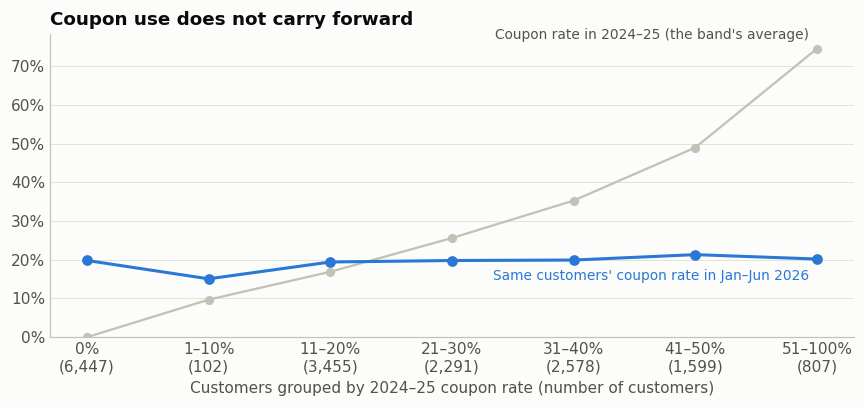

In [ ]:
outcomes = pd.read_csv(OUTPUT_DIR / "holdout_outcomes_calibration.csv", index_col="customer_id")
outcomes["kmeans_segment"] = pd.Categorical(outcomes.kmeans_segment, categories=SEGMENT_ORDER, ordered=True)
by_cal_segment = outcomes.join(h).groupby("kmeans_segment", observed=True).agg(
    customers=("coupon_rate", "size"), coupon_rate_2024_25=("coupon_rate", "mean"),
    coupon_rate_2026=("coupon_rate_2026", "mean"))
display(by_cal_segment.style.format({"customers": "{:,.0f}", "coupon_rate_2024_25": "{:.1%}", "coupon_rate_2026": "{:.1%}"}))

bands = pd.cut(carry.coupon_rate, bins=[-0.01, 0, 0.1, 0.2, 0.3, 0.4, 0.5, 1.0],
               labels=["0%", "1–10%", "11–20%", "21–30%", "31–40%", "41–50%", "51–100%"])
band_table = carry.groupby(bands, observed=True).agg(customers=("coupon_rate", "size"),
                                                     rate_2024_25=("coupon_rate", "mean"),
                                                     rate_2026=("coupon_rate_2026", "mean"))
fig, ax = plt.subplots(figsize=(8, 3.8))
x = np.arange(len(band_table))
ax.plot(x, band_table.rate_2024_25, color=ps.BASELINE, marker="o", markersize=5, linewidth=1.5)
ax.plot(x, band_table.rate_2026, color=ps.SERIES[0], marker="o", markersize=6)
ax.annotate("Coupon rate in 2024–25 (the band's average)", xy=(x[-1], band_table.rate_2024_25.iloc[-1]), xytext=(-5, 6),
            textcoords="offset points", ha="right", fontsize=9, color=ps.TEXT_SECONDARY)
ax.annotate("Same customers' coupon rate in Jan–Jun 2026", xy=(x[-1], band_table.rate_2026.iloc[-1]), xytext=(-5, -14),
            textcoords="offset points", ha="right", fontsize=9, color=ps.SERIES[0])
ax.set_xticks(x, [f"{b}\n({n:,})" for b, n in zip(band_table.index, band_table.customers)])
ax.set_xlabel("Customers grouped by 2024–25 coupon rate (number of customers)")
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_ylim(0, None)
ax.set_title("Coupon use does not carry forward", loc="left")
fig.tight_layout()
ps.save(fig, "Notebook 5_coupon_persistence")
plt.show()

**Finding: coupon use is not a customer trait in this data. It behaves like chance on each order.**

- **Customers differ in coupon rate no more than luck alone would produce.** The observed variance is 0.0319, against 0.0317 expected if every order had the same 20.1% chance of a coupon (ratio 1.01).
- **Coupon use does not carry forward.** Among 17,279 customers with 2 or more orders in 2026, the rank correlation between their 2024–25 and 2026 coupon rates is +0.008 (between −0.003 and +0.035 within each tier). Customers who used coupons on more than half their orders in 2024–25 used them on about 20% in 2026, the same as customers who had never used one.
- **The calibration Coupon-led buyers used a coupon on 61.8% of orders in 2024–25, and on 20.9% in 2026.** Every calibration segment ended up between 19.4% and 20.9%.

**Implication for Notebook 3:** the **Coupon-led buyers** segment describes customers who happened to use many coupons in the period observed, not customers who need coupons to buy. Apart from coupon use, they buy much like Core high-value regulars *[Notebook 3]*, and they should be treated that way. Coupon rate was kept as a clustering feature because the project brief required it, at a cost to cluster separation that Notebook 3 already reported *[Notebook 3, Section 3]*. This result shows why that cost bought no lasting insight.

## 4. Do coupon users keep buying?

Calibration customers (Notebook 4) are split into three groups by their 2024–25 coupon rate:

- **None:** never used a coupon;
- **Some:** coupon rate above 0 and up to the median rate of coupon users;
- **Heavy:** above that median.

Two things would distort a simple comparison. Tier drives both lapse and spend *[Notebook 4, Section 4.1]*, and customers with more orders have more chances to use a coupon. So the groups are compared **within strata of tier × number of calibration orders** (capped at 10), and each group's rate is re-weighted to the same mix of strata (direct standardisation). The result shows what each group's lapse rate and spend would be if all three groups had the same tiers and order counts.

In [8]:
cal = outcomes.join(calib[["orders_placed"]])
coupon_median = cal.loc[cal.coupon_rate > 0, "coupon_rate"].median()
cal["coupon_group"] = pd.Categorical(np.select([cal.coupon_rate == 0, cal.coupon_rate <= coupon_median], ["None", "Some"], "Heavy"),
                                     categories=["None", "Some", "Heavy"], ordered=True)
cal["stratum"] = cal.customer_tier + " | " + cal.orders_placed.clip(upper=10).astype(str)
print(f"Median coupon rate among calibration coupon users: {coupon_median:.1%}")


def standardised(table, metric, group="coupon_group"):
    # Each group's metric, re-weighted to the overall mix of strata (strata where every group appears)
    cell = table.pivot_table(index="stratum", columns=group, values=metric, aggfunc="mean", observed=False).dropna()
    weights = table.stratum.value_counts().reindex(cell.index)
    return cell.mul(weights, axis=0).sum() / weights.sum()


def coupon_outcomes(table):
    raw = table.groupby("coupon_group", observed=False).agg(customers=("lapsed", "size"), lapse_rate=("lapsed", "mean"),
                                                             spend_2026=("holdout_spend", "mean"))
    raw["adjusted_lapse_rate"] = standardised(table, "lapsed")
    raw["adjusted_spend_2026"] = standardised(table, "holdout_spend")
    return raw


OUTCOME_FORMAT = {"customers": "{:,.0f}", "lapse_rate": "{:.1%}", "adjusted_lapse_rate": "{:.1%}",
                  "spend_2026": "₹{:,.0f}", "adjusted_spend_2026": "₹{:,.0f}"}
cal["lapsed"] = cal.lapsed.astype(float)
overall_outcomes = coupon_outcomes(cal)
print("All calibration customers")
display(overall_outcomes.style.format(OUTCOME_FORMAT))
tier_outcomes = {}
for tier in TIER_ORDER:
    sub = cal[cal.customer_tier == tier]
    tier_outcomes[tier] = coupon_outcomes(sub)
    print(tier)
    display(tier_outcomes[tier].style.format(OUTCOME_FORMAT))

Median coupon rate among calibration coupon users: 28.6%
All calibration customers


,customers,lapse_rate,spend_2026,adjusted_lapse_rate,adjusted_spend_2026
coupon_group,,,,,
None,"14,763",22.7%,"₹31,673",22.9%,"₹32,013"
Some,"13,250",23.0%,"₹32,383",22.9%,"₹32,519"
Heavy,"11,418",23.1%,"₹31,478",23.0%,"₹31,534"


Silver


,customers,lapse_rate,spend_2026,adjusted_lapse_rate,adjusted_spend_2026
coupon_group,,,,,
None,"2,722",35.2%,"₹4,824",35.5%,"₹3,961"
Some,"1,067",37.0%,"₹3,990",36.9%,"₹4,035"
Heavy,"1,797",36.6%,"₹5,048",35.7%,"₹3,726"


Gold


,customers,lapse_rate,spend_2026,adjusted_lapse_rate,adjusted_spend_2026
coupon_group,,,,,
None,"2,759",24.3%,"₹12,366",25.6%,"₹9,613"
Some,"1,869",27.6%,"₹8,861",27.4%,"₹9,074"
Heavy,"1,976",26.9%,"₹11,030",28.4%,"₹8,371"


Platinum


,customers,lapse_rate,spend_2026,adjusted_lapse_rate,adjusted_spend_2026
coupon_group,,,,,
None,"9,282",18.5%,"₹45,285",20.9%,"₹39,497"
Some,"10,314",20.7%,"₹39,583",20.4%,"₹40,253"
Heavy,"7,645",19.0%,"₹42,976",20.5%,"₹39,137"


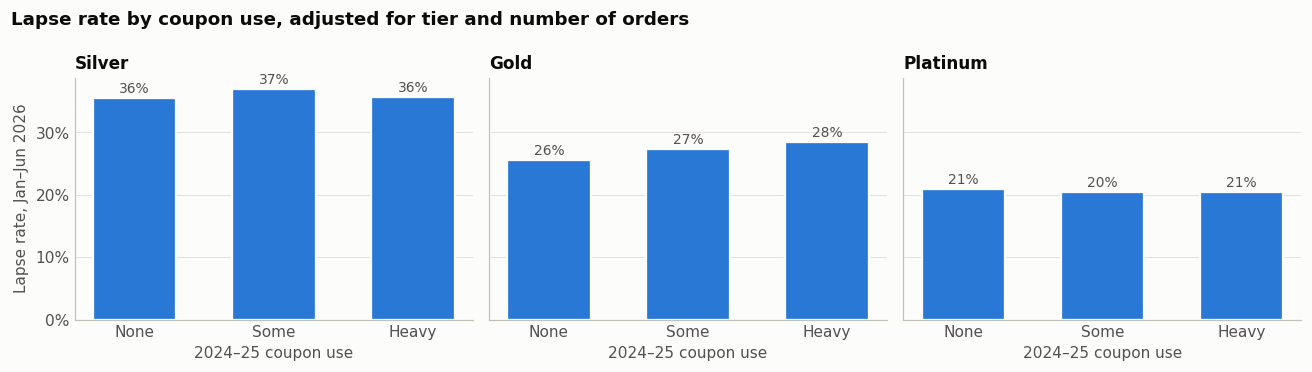

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True)
for ax, tier in zip(axes, TIER_ORDER):
    t = tier_outcomes[tier]
    ax.bar(t.index.astype(str), t.adjusted_lapse_rate, width=0.6, **ps.bar_kwargs())
    for i, v in enumerate(t.adjusted_lapse_rate):
        ax.text(i, v + 0.008, f"{v:.0%}", ha="center", fontsize=9, color=ps.TEXT_SECONDARY)
    ax.set_title(tier, fontsize=11)
    ax.set_xlabel("2024–25 coupon use")
    ax.grid(axis="x", visible=False)
axes[0].yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[0].set_ylabel("Lapse rate, Jan–Jun 2026")
fig.suptitle("Lapse rate by coupon use, adjusted for tier and number of orders", x=0.01, ha="left",
             fontsize=12, fontweight="semibold")
fig.tight_layout()
ps.save(fig, "Notebook 5_coupon_lapse")
plt.show()

**Finding: coupon users do not keep buying any more than non-users.**

- **All calibration customers:** after adjusting for tier and order count, the lapse rate is 22.9% for non-users, 22.9% for occasional users and 23.0% for heavy users. 2026 spend per customer is ₹32,013, ₹32,519 and ₹31,534.
- **Within each tier the differences are small and point in no consistent direction:**
  - Silver: 35.5%, 36.9% and 35.7%.
  - Gold: 25.6%, 27.4% and 28.4%. Gold coupon users lapsed slightly *more*.
  - Platinum: 20.9%, 20.4% and 20.5%.

**Answer to the executive question, "Are coupons building loyalty, or subsidising people who would buy anyway?":** on this evidence, coupons subsidise people who would buy anyway. They are not linked to bigger baskets (Section 2), to continued buying (this section), or to any lasting customer habit (Section 3). As the charter requires, these are **associations**: customers choose when to use a coupon, so only a controlled trial can prove cause.

## 5. Percentage against flat coupons

`SAVE10` takes 10% off the order; `FLAT50` and `DIWALI100` take a fixed ₹50 or ₹100 (Section 1). Two questions:

- **Do they attract different customers?** For customers who used coupons, does the share of their coupons that were `SAVE10` relate to their basket size or Electronics share?
- **Where does the cost land?** Discount by coupon type and category.

In [10]:
users = current[current.pct_coupon_share.notna()]
print(f"Customers who used a coupon: {len(users):,}")
for f in ["aov", "electronics_share", "frequency"]:
    print(f"  Rank correlation, SAVE10 share of a customer's coupons vs {f}: {spearmanr(users.pct_coupon_share, users[f])[0]:+.3f}")

by_type = valid[valid.coupon_used].groupby("coupon_code").agg(
    orders=("order_id", "size"), mean_order_value=("order_value", "mean"), discount=("coupon_discount", "sum"),
    mean_discount=("coupon_discount", "mean"))
by_type["share_of_discount"] = by_type.discount / by_type.discount.sum()
display(by_type.style.format({"orders": "{:,.0f}", "mean_order_value": "₹{:,.0f}", "discount": lambda v: f"₹{v / 1e6:,.2f} M",
                              "mean_discount": "₹{:,.0f}", "share_of_discount": "{:.1%}"}))

save10_by_category = valid[valid.coupon_code == "SAVE10"].groupby("category").agg(
    orders=("order_id", "size"), discount=("coupon_discount", "sum"), mean_discount=("coupon_discount", "mean"))
save10_by_category["share_of_save10_discount"] = save10_by_category.discount / save10_by_category.discount.sum()
save10_by_category.sort_values("discount", ascending=False).style.format(
    {"orders": "{:,.0f}", "discount": lambda v: f"₹{v / 1e6:,.2f} M", "mean_discount": "₹{:,.0f}",
     "share_of_save10_discount": "{:.1%}"})

Customers who used a coupon: 28,621
  Rank correlation, SAVE10 share of a customer's coupons vs aov: -0.010
  Rank correlation, SAVE10 share of a customer's coupons vs electronics_share: +0.002
  Rank correlation, SAVE10 share of a customer's coupons vs frequency: +0.001


,orders,mean_order_value,discount,mean_discount,share_of_discount
coupon_code,,,,,
DIWALI100,"11,353","₹24,610",₹1.14 M,₹100,2.0%
FLAT50,"11,343","₹24,209",₹0.57 M,₹50,1.0%
SAVE10,"22,505","₹24,313",₹54.72 M,"₹2,431",97.0%


,orders,discount,mean_discount,share_of_save10_discount
category,,,,
Electronics,"6,097",₹40.06 M,"₹6,570",73.2%
Home,"3,017",₹6.65 M,"₹2,203",12.1%
Sports,"2,598",₹4.19 M,"₹1,613",7.7%
Fashion,"4,367",₹2.92 M,₹670,5.3%
Grocery,"2,999",₹0.37 M,₹123,0.7%
Beauty,"1,532",₹0.35 M,₹229,0.6%
Books,"1,895",₹0.18 M,₹93,0.3%


In [11]:
# What a cap on SAVE10 would have saved, assuming customers order the same way (Section 2 found coupons barely change order value)
save10 = valid[valid.coupon_code == "SAVE10"]
caps = pd.DataFrame([{"cap": cap,
                      "orders_affected": (save10.coupon_discount > cap).sum(),
                      "discount_saved": (save10.coupon_discount - cap).clip(lower=0).sum()} for cap in (500, 1_000, 2_000, 5_000)])
caps["share_of_all_coupon_cost"] = caps.discount_saved / valid.coupon_discount.sum()
caps.set_index("cap").style.format({"orders_affected": "{:,.0f}", "discount_saved": lambda v: f"₹{v / 1e6:,.2f} M",
                                    "share_of_all_coupon_cost": "{:.1%}"}).format_index("₹{:,.0f}")

,orders_affected,discount_saved,share_of_all_coupon_cost
cap,,,
₹500,"13,258",₹46.45 M,82.3%
"₹1,000","10,469",₹40.56 M,71.9%
"₹2,000","7,315",₹31.88 M,56.5%
"₹5,000","3,786",₹16.31 M,28.9%


**Findings:**

- **Percentage and flat coupons attract the same customers.** The share of a customer's coupons that were `SAVE10` is unrelated to their basket size (ρ = −0.010), Electronics share (+0.002) or number of orders (+0.001). Orders using each coupon have the same average value (₹24,209–₹24,610).
- **The cost lands on Electronics:**
  - `SAVE10` accounts for 97.0% of all coupon cost (₹54.72 M).
  - 73.2% of that falls on Electronics orders, at an average of ₹6,570 per order, against ₹93–₹2,203 in other categories.
- **A cap on `SAVE10` would remove most of the cost.** If customers ordered the same way, a ₹1,000 cap would have saved ₹40.56 M (71.9% of all coupon cost) and affected 10,469 orders. A ₹2,000 cap would have saved ₹31.88 M (56.5%). That assumption is reasonable here because coupons barely change order value (Section 2). In practice, some customers might buy less without the larger discount, which a trial would show.

### Coupon efficiency by segment

The table brings Part A together for each Notebook 3 segment. Lapse rates for coupon users and non-users use the calibration segments and are adjusted for tier and order count as in Section 4.

In [12]:
seg_rows = {}
for segment in SEGMENT_ORDER:
    sub = cal[cal.kmeans_segment == segment].assign(
        user=lambda t: np.where(t.coupon_group == "None", "non_user", "user"))
    adj = standardised(sub, "lapsed", group="user")
    seg_rows[segment] = {"non_users": (sub.user == "non_user").sum(),
                         "adjusted_lapse_users": adj.get("user", np.nan),
                         "adjusted_lapse_non_users": adj.get("non_user", np.nan)}
lapse_by_seg = pd.DataFrame(seg_rows).T
lapse_by_seg["lapse_difference"] = lapse_by_seg.adjusted_lapse_users - lapse_by_seg.adjusted_lapse_non_users

efficiency = cost_by_segment[["coupon_rate", "discount", "coupon_cost_rate", "discount_share_of_revenue",
                              "save10_share_of_discount"]].join(within_by_segment[["gap"]].rename(columns={"gap": "order_value_gap"})).join(lapse_by_seg)
efficiency.index.name = "kmeans_segment"
efficiency.style.format({"coupon_rate": "{:.1%}", "discount": lambda v: f"₹{v / 1e6:,.2f} M", "coupon_cost_rate": "{:.2%}",
                         "discount_share_of_revenue": "{:.2%}", "save10_share_of_discount": "{:.1%}",
                         "order_value_gap": "{:+.1%}", "non_users": "{:,.0f}", "adjusted_lapse_users": "{:.1%}", "adjusted_lapse_non_users": "{:.1%}",
                         "lapse_difference": "{:+.1%}"}, na_rep="–")

,coupon_rate,discount,coupon_cost_rate,discount_share_of_revenue,save10_share_of_discount,order_value_gap,non_users,adjusted_lapse_users,adjusted_lapse_non_users,lapse_difference
kmeans_segment,,,,,,,,,,
Core high-value regulars,13.2%,₹16.95 M,0.71%,0.71%,97.7%,+2.6%,"3,344",23.5%,23.9%,-0.4%
Big-ticket Electronics buyers,18.5%,₹8.97 M,0.94%,0.95%,98.4%,+0.0%,"2,347",23.5%,22.0%,+1.5%
Coupon-led buyers,41.7%,₹19.93 M,2.15%,2.20%,97.3%,+1.1%,0,22.8%,–,–
Frequent everyday shoppers,17.9%,₹4.40 M,0.97%,0.98%,93.1%,+1.2%,"1,993",21.9%,22.9%,-1.0%
Occasional light shoppers,18.7%,₹2.49 M,0.98%,0.99%,92.1%,+1.2%,"2,935",22.2%,22.5%,-0.3%
Lapsed high-value customers,16.5%,₹3.35 M,0.88%,0.89%,97.4%,+3.5%,"1,664",22.9%,23.3%,-0.3%
Lapsed light buyers,24.8%,₹0.32 M,1.44%,1.46%,88.1%,-2.1%,"2,480",20.2%,22.3%,-2.2%


**Coupon efficiency by segment**

| Segment | Cost (25 months) | Cost rate | Order value gap | Lapse, users vs non-users | Recommendation |
|---|---|---|---|---|---|
| Core high-value regulars | ₹16.95 M | 0.71% | +2.6% | 23.5% vs 23.9% | **Cap `SAVE10`** |
| Big-ticket Electronics buyers | ₹8.97 M | 0.94% | +0.0% | 23.5% vs 22.0% | **Cap `SAVE10`** |
| Coupon-led buyers | ₹19.93 M | 2.15% | +1.1% | – (no non-users) | **Cap `SAVE10`**; do not treat as a coupon segment |
| Frequent everyday shoppers | ₹4.40 M | 0.97% | +1.2% | 21.9% vs 22.9% | Keep (low cost) |
| Occasional light shoppers | ₹2.49 M | 0.98% | +1.2% | 22.2% vs 22.5% | Keep (low cost) |
| Lapsed high-value customers | ₹3.35 M | 0.88% | +3.5% | 22.9% vs 23.3% | **Cap `SAVE10`** |
| Lapsed light buyers | ₹0.32 M | 1.44% | −2.1% | 20.2% vs 22.3% | Keep flat coupons, with a minimum order value |

No segment is recommended for *more* coupon targeting, because no segment shows a reliable link between coupons and larger baskets or continued buying. The next step the charter calls for is a **controlled trial**: cap `SAVE10` for a random half of customers and compare their spend and lapse rate with the other half over six months.

# Part B: Electronics cross-sell

## 6. Electronics dependence groups

Groups by Electronics share of valid orders over the full period, as in Notebook 1 *[Notebook 1, Q6]*:

- **Electronics-led:** more than 50% of valid orders in Electronics;
- **Mixed:** some Electronics, up to 50%;
- **Non-Electronics:** no Electronics orders.

In [ ]:
current["electronics_group"] = pd.Categorical(
    np.select([current.electronics_share > 0.5, current.electronics_share > 0], ["Electronics-led", "Mixed"], "Non-Electronics"),
    categories=["Electronics-led", "Mixed", "Non-Electronics"], ordered=True)
counts = current.electronics_group.value_counts()
assert counts["Electronics-led"] == 4_992 and counts["Non-Electronics"] == 12_758, "Differs from Notebook 1, Q6"

GROUP_ORDER = ["Electronics-led", "Mixed", "Non-Electronics"]
groups = current.groupby("electronics_group", observed=True).agg(
    customers=("monetary", "size"), revenue=("monetary", "sum"), median_spend=("monetary", "median"),
    median_aov=("aov", "median"), platinum_share=("customer_tier", lambda t: (t == "Platinum").mean()),
    categories_bought=("category_breadth", "mean"))
groups.insert(1, "share_of_customers", groups.customers / groups.customers.sum())
groups.insert(3, "share_of_revenue", groups.revenue / groups.revenue.sum())
display(groups.style.format({"customers": "{:,.0f}", "share_of_customers": "{:.1%}", "revenue": lambda v: f"₹{v / 1e6:,.1f} M",
                             "share_of_revenue": "{:.1%}", "median_spend": "₹{:,.0f}", "median_aov": "₹{:,.0f}",
                             "platinum_share": "{:.1%}", "categories_bought": "{:.2f}"}))
display(pd.crosstab(current.kmeans_segment, current.electronics_group).style.format("{:,.0f}"))
display(pd.crosstab(current.customer_tier, current.electronics_group).style.format("{:,.0f}"))

electronics_revenue = valid.assign(elec=np.where(valid.category == "Electronics", valid.total_amount, 0)).groupby(
    "kmeans_segment", observed=True).agg(revenue=("total_amount", "sum"), electronics=("elec", "sum"))
electronics_revenue["electronics_share_of_revenue"] = electronics_revenue.electronics / electronics_revenue.revenue
electronics_revenue.style.format({"revenue": lambda v: f"₹{v / 1e6:,.1f} M", "electronics": lambda v: f"₹{v / 1e6:,.1f} M",
                                  "electronics_share_of_revenue": "{:.1%}"})

,customers,share_of_customers,revenue,share_of_revenue,median_spend,median_aov,platinum_share,categories_bought
electronics_group,,,,,,,,
Electronics-led,"4,992",12.5%,"₹1,192.2 M",22.4%,"₹217,246","₹43,416",93.7%,2.20
Mixed,"22,098",55.5%,"₹3,595.3 M",67.5%,"₹141,268","₹24,371",86.3%,2.80
Non-Electronics,"12,758",32.0%,₹540.7 M,10.1%,"₹33,614","₹7,131",28.1%,2.25


electronics_group,Electronics-led,Mixed,Non-Electronics
kmeans_segment,,,
Core high-value regulars,"1,262","9,830",38
Big-ticket Electronics buyers,"2,927","2,141",0
Coupon-led buyers,430,"4,806",390
Frequent everyday shoppers,1,"2,371","4,434"
Occasional light shoppers,0,548,"5,494"
Lapsed high-value customers,359,"2,376",442
Lapsed light buyers,13,26,"1,960"


electronics_group,Electronics-led,Mixed,Non-Electronics
customer_tier,,,
Silver,116,835,"4,856"
Gold,197,"2,182","4,313"
Platinum,"4,679","19,081","3,589"


,revenue,electronics,electronics_share_of_revenue
kmeans_segment,,,
Core high-value regulars,"₹2,377.7 M","₹1,903.6 M",80.1%
Big-ticket Electronics buyers,₹941.7 M,₹862.2 M,91.6%
Coupon-led buyers,₹906.9 M,₹683.8 M,75.4%
Frequent everyday shoppers,₹449.0 M,₹113.3 M,25.2%
Occasional light shoppers,₹252.6 M,₹20.8 M,8.2%
Lapsed high-value customers,₹378.0 M,₹286.1 M,75.7%
Lapsed light buyers,₹22.2 M,₹0.3 M,1.2%


**Findings (reproducing Notebook 1's group sizes):**

| Group | Customers | Revenue | Median spend | Platinum |
|---|---|---|---|---|
| Electronics-led | 4,992 (12.5%) | ₹1,192.2 M (22.4%) | ₹217,246 | 93.7% |
| Mixed | 22,098 (55.5%) | ₹3,595.3 M (67.5%) | ₹141,268 | 86.3% |
| Non-Electronics | 12,758 (32.0%) | ₹540.7 M (10.1%) | ₹33,614 | 28.1% |

- **Electronics dependence is spread across the high-value segments.** Electronics is 91.6% of revenue for Big-ticket Electronics buyers, 80.1% for Core high-value regulars, 75.4% for Coupon-led buyers and 75.7% for Lapsed high-value customers. It is 25.2% or less for the other three segments.
- **Electronics-led customers are concentrated in two segments:** Big-ticket Electronics buyers (2,927) and Core high-value regulars (1,262).
- **They are high-value and mostly Platinum** (93.7%), with the highest median spend of the three groups.

## 7. Which categories are bought alongside Electronics?

For each customer, the set of categories they have bought (valid orders, full period). **Lift** compares how often two categories appear in the same customer's set with how often they would if customers chose categories independently. A lift above 1 means the pair goes together more than chance; below 1, less.

In [14]:
basket = pd.crosstab(valid.customer_id, valid.category).gt(0)
CATEGORY_ORDER = basket.sum().sort_values(ascending=False).index.tolist()
basket = basket[CATEGORY_ORDER]
share = basket.mean()
together = basket.T.astype(int) @ basket.astype(int) / len(basket)
lift = together / np.outer(share, share)
lift = pd.DataFrame(lift, index=CATEGORY_ORDER, columns=CATEGORY_ORDER)

others = [c for c in CATEGORY_ORDER if c != "Electronics"]
led = basket.loc[current.index[current.electronics_group == "Electronics-led"]]
alongside = pd.DataFrame({
    "share_of_all_customers": share[others],
    "share_of_electronics_buyers": basket.loc[basket.Electronics, others].mean(),
    "share_of_electronics_led": led[others].mean(),
    "lift_with_electronics": lift.loc["Electronics", others],
}).sort_values("share_of_electronics_led", ascending=False)
alongside.style.format({c: "{:.1%}" for c in alongside.columns if c.startswith("share")} | {"lift_with_electronics": "{:.3f}"})

,share_of_all_customers,share_of_electronics_buyers,share_of_electronics_led,lift_with_electronics
Fashion,50.9%,63.4%,46.2%,1.246
Sports,29.8%,37.1%,25.8%,1.246
Books,20.9%,26.0%,19.0%,1.244
Home,34.1%,21.4%,14.9%,0.627
Grocery,34.1%,21.2%,14.4%,0.621
Beauty,17.0%,0.0%,0.0%,0.000


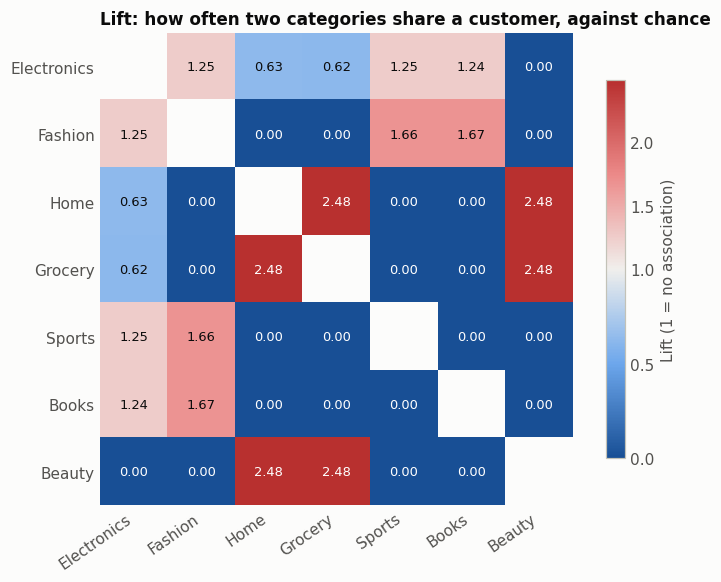

In [ ]:
# TwoSlopeNorm: centre the blue-grey-red scale on a lift of 1 (no association)
from matplotlib.colors import TwoSlopeNorm

fig, ax = plt.subplots(figsize=(7, 5.4))
masked = lift.where(~np.eye(len(lift), dtype=bool))
im = ax.imshow(masked.values, cmap=ps.DIVERGING, norm=TwoSlopeNorm(vcenter=1, vmin=0, vmax=np.nanmax(masked.values)))
ax.set_xticks(range(len(CATEGORY_ORDER)), CATEGORY_ORDER, rotation=35, ha="right")
ax.set_yticks(range(len(CATEGORY_ORDER)), CATEGORY_ORDER)
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
for i in range(len(CATEGORY_ORDER)):
    for j in range(len(CATEGORY_ORDER)):
        if i != j:
            v = masked.values[i, j]
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8.5,
                    color="white" if (v < 0.3 or v > 2) else ps.TEXT_PRIMARY)
ax.set_title("Lift: how often two categories share a customer, against chance", loc="left", fontsize=11)
fig.colorbar(im, ax=ax, shrink=0.8, label="Lift (1 = no association)")
fig.tight_layout()
ps.save(fig, "Notebook 5_category_lift")
plt.show()

The many zeros in the lift chart suggest that customers' category sets follow a small number of fixed combinations. The table below lists every combination of categories that any customer has bought.

In [16]:
category_sets = basket.apply(lambda row: " + ".join(c for c in CATEGORY_ORDER if row[c]), axis=1)
set_counts = category_sets.value_counts().rename("customers").to_frame()
set_counts["share"] = set_counts.customers / set_counts.customers.sum()
print(f"Distinct category combinations: {len(set_counts)} (out of {2 ** len(CATEGORY_ORDER) - 1} possible)")
set_counts.style.format({"customers": "{:,.0f}", "share": "{:.1%}"})

Distinct category combinations: 21 (out of 127 possible)


,customers,share
Electronics + Fashion + Sports,"8,520",21.4%
Electronics + Fashion + Books,"5,992",15.0%
Electronics + Home + Grocery,"4,888",12.3%
Home + Grocery + Beauty,"4,864",12.2%
Electronics + Fashion,"2,672",6.7%
Home + Grocery,"1,762",4.4%
Electronics + Sports,"1,539",3.9%
Fashion + Sports,"1,537",3.9%
Fashion + Books,"1,091",2.7%
Electronics + Books,"1,046",2.6%


**Findings:**

- **Electronics buyers lean towards Fashion, Sports and Books** (lift 1.24–1.25). They lean *away* from Home and Grocery (0.62–0.63), and **no Electronics buyer has ever bought Beauty** (lift 0).
- **Customers' category sets follow fixed patterns.** Only **21 of the 127 possible combinations** occur. All of them are a full set, or part of a set, of four three-category groups:
  - Electronics + Fashion + Sports (21.4% of customers);
  - Electronics + Fashion + Books (15.0%);
  - Electronics + Home + Grocery (12.3%);
  - Home + Grocery + Beauty (12.2%).

  Every customer's categories fit inside one of these four groups. This is far more regular than real shopping, and fits the first project's note that the data is likely synthetic *[Report §5]*.

**Implication:** the first project recommended cross-selling **Home and Sports** to Electronics buyers *[Report §4]*. Sports is supported. Home is not: Electronics buyers buy Home less often than chance, and only those already in the Electronics + Home + Grocery pattern ever add it.

## 8. Which category do customers actually add?

Co-occurrence shows what customers already combine. A stronger guide to the next category is what customers **actually added**. For every customer with valid orders both in 2024–25 (calibration) and in Jan–Jun 2026, any category bought in 2026 but not in 2024–25 counts as an addition.

Notebook 1 found that no customer buys from more than 3 categories *[Notebook 1, Q7]*, so only customers with 1 or 2 categories in 2024–25 had room to add one. The **add rate** for a category is the share of customers who could have added it (they had room and had not bought it yet) and did.

In [17]:
v_cal = valid[valid.order_date <= cf.CALIBRATION_END]
v_hold = valid[valid.order_date >= cf.HOLDOUT_START]
sets_cal = pd.crosstab(v_cal.customer_id, v_cal.category).gt(0).reindex(columns=CATEGORY_ORDER, fill_value=False)
sets_hold = pd.crosstab(v_hold.customer_id, v_hold.category).gt(0).reindex(columns=CATEGORY_ORDER, fill_value=False)
both = sets_cal.index.intersection(sets_hold.index)
sets_cal, sets_hold = sets_cal.loc[both], sets_hold.loc[both]
added = sets_hold & ~sets_cal
n_cal = sets_cal.sum(axis=1)
assert (added.sum(axis=1)[n_cal >= 3] == 0).all(), "A customer with 3 categories added a fourth"

cal_elec_share = v_cal.groupby("customer_id").category.apply(lambda c: (c == "Electronics").mean()).reindex(both)
cal_group = pd.Series(np.select([cal_elec_share > 0.5, cal_elec_share > 0], ["Electronics-led", "Mixed"], "Non-Electronics"),
                      index=both)
room = n_cal < 3
print(f"Customers ordering in both periods: {len(both):,}; with room to add a category: {room.sum():,} ({room.mean():.1%})")
print(f"Of those with room, share who added at least one category in Jan–Jun 2026: {added[room].any(axis=1).mean():.1%}")

add_rates = {}
for grp in GROUP_ORDER:
    eligible = room & (cal_group == grp)
    add_rates[grp] = {c: added.loc[eligible & ~sets_cal[c], c].mean() for c in others}
    add_rates[grp]["customers_with_room"] = eligible.sum()
    add_rates[grp]["added_any"] = added[eligible].any(axis=1).mean()
add_rates = pd.DataFrame(add_rates).T
display(add_rates.style.format({**{c: "{:.1%}" for c in others}, "customers_with_room": "{:,.0f}", "added_any": "{:.1%}"}))

Customers ordering in both periods: 28,965; with room to add a category: 16,150 (55.8%)
Of those with room, share who added at least one category in Jan–Jun 2026: 56.0%


,Fashion,Home,Grocery,Sports,Books,Beauty,customers_with_room,added_any
Electronics-led,32.8%,7.7%,8.3%,16.1%,11.8%,0.0%,"3,241",58.2%
Mixed,30.8%,6.3%,7.0%,13.4%,8.0%,0.0%,"4,353",48.2%
Non-Electronics,6.8%,14.3%,14.1%,3.3%,2.3%,9.2%,"8,556",59.0%


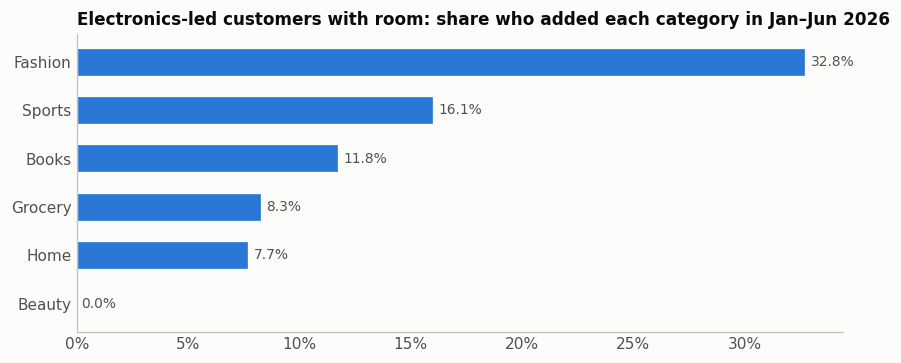

In [ ]:
led_rates = add_rates.loc["Electronics-led", others].astype(float).sort_values()
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.barh(led_rates.index, led_rates.values, height=0.6, **ps.bar_kwargs())
for y, v in enumerate(led_rates.values):
    ax.text(v + 0.002, y, f"{v:.1%}", va="center", fontsize=9, color=ps.TEXT_SECONDARY)
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:.0%}"))
ax.grid(axis="y", visible=False)
ax.set_title("Electronics-led customers with room: share who added each category in Jan–Jun 2026", loc="left", fontsize=11)
fig.tight_layout()
ps.save(fig, "Notebook 5_category_adds")
plt.show()

**Findings:**

- **Customers add categories on their own, often.** Of the 16,150 customers who ordered in both periods and had room (fewer than 3 categories), 56.0% added at least one new category in Jan–Jun 2026 without any campaign. Among Electronics-led customers with room it was 58.2%.
- **What Electronics-led customers added:** Fashion (32.8% of those who could), Sports (16.1%), Books (11.8%), Grocery (8.3%), Home (7.7%) and never Beauty.
- **Non-Electronics customers add different categories:** mainly Home (14.3%) and Grocery (14.1%), which matches the four patterns above.

**Implication:** with a natural add rate this high, a cross-sell campaign can only take credit for additions **above** that rate. It needs a control group to measure them.

## 9. Are Electronics-led customers a bigger risk?

The charter's hypothesis is that high-spending, mostly-Electronics customers are the biggest concentration risk. Using the calibration Electronics groups, their Jan–Jun 2026 lapse rate and spend are compared with other customers **in the same tier**.

In [19]:
cal_share = calib.electronics_share.reindex(cal.index)
cal["electronics_group"] = pd.Categorical(
    np.select([cal_share > 0.5, cal_share > 0], ["Electronics-led", "Mixed"], "Non-Electronics"),
    categories=GROUP_ORDER, ordered=True)
display(cal.electronics_group.value_counts().reindex(GROUP_ORDER).rename("calibration_customers").to_frame().T)
risk = cal.pivot_table(index="electronics_group", columns="customer_tier", values=["lapsed", "holdout_spend"],
                       aggfunc="mean", observed=False)
risk = risk.reindex(columns=pd.MultiIndex.from_product([["lapsed", "holdout_spend"], TIER_ORDER]))
risk.style.format({**{("lapsed", t): "{:.1%}" for t in TIER_ORDER}, **{("holdout_spend", t): "₹{:,.0f}" for t in TIER_ORDER}})

electronics_group,Electronics-led,Mixed,Non-Electronics
calibration_customers,5457,18880,15094


**Finding: Electronics-led customers are not a bigger lapse risk than mixed customers in the same tier.**

| Tier | Electronics-led | Mixed | Non-Electronics |
|---|---|---|---|
| Silver | 41.5% | 41.8% | 35.1% |
| Gold | 36.5% | 34.6% | 22.4% |
| Platinum | 22.1% | 21.6% | 10.8% |

*(Jan–Jun 2026 lapse rate, calibration groups.)*

- **Electronics-led and mixed customers lapse at almost the same rate** in every tier.
- **Non-Electronics customers lapse less** in every tier, most clearly in Platinum (10.8%). That fits the mean reversion found in Notebook 4 *[Notebook 4, Section 4.1]*: customers whose past spend was low for their tier tend to buy more later, and non-Electronics customers have low spend.

The charter's hypothesis is therefore only half right. Electronics-led customers are the **biggest concentration of value** (₹1,192.2 M from 12.5% of customers), but they are not more likely to leave. The concentration risk is about dependence on one category's demand and margins, not about these customers lapsing.

## 10. Who to target, with which category, and what it could be worth

**Target group:** Electronics-led customers (as at 30 Jun 2026) who buy from fewer than 3 categories, so they still have room to add one. Each customer's **next category** is the one they have not bought yet with the highest **expected value per customer**: the add rate among Electronics-led customers (Section 8) × the category's average valid-order value over the full period. This favours a category that is both likely to be added and worth adding. Section 7 showed that customers only ever buy one of 21 category combinations, so a category is only suggested if adding it gives a combination that other customers already buy.

**Sizing assumption:** if a share of the target group (5%, 10% or 20%) places **one extra order** in their next category, revenue rises by take-up × customers × the category's average order value. Section 8 shows that some customers add a category without any campaign, so a real campaign should be judged only on what it adds **above that natural rate**, measured against a control group.

In [20]:
category_aov = valid.groupby("category").total_amount.mean()
expected_value = (led_rates * category_aov.reindex(led_rates.index)).sort_values(ascending=False)
display(pd.DataFrame({"add_rate": led_rates, "average_order_value": category_aov.reindex(led_rates.index),
                      "expected_value_per_customer": expected_value}).sort_values("expected_value_per_customer", ascending=False)
        .style.format({"add_rate": "{:.1%}", "average_order_value": "₹{:,.0f}", "expected_value_per_customer": "₹{:,.0f}"}))
preference = expected_value.index.tolist()

targets = current[(current.electronics_group == "Electronics-led") & (current.category_breadth < 3)].copy()
owned = basket.reindex(targets.index)
observed_sets = {frozenset(s.split(" + ")) for s in set_counts.index}


def next_category(row):
    have = {c for c in CATEGORY_ORDER if row[c]}
    return next((c for c in preference if c not in have and frozenset(have | {c}) in observed_sets), None)


targets["next_category"] = [next_category(owned.loc[i]) for i in targets.index]
print("Current category sets of the target group:")
display(category_sets.reindex(targets.index).value_counts().rename("customers").to_frame().T)
assert targets.next_category.notna().all()
targets["next_category_aov"] = targets.next_category.map(category_aov)
print(f"Target group: {len(targets):,} Electronics-led customers with fewer than 3 categories "
      f"({len(targets) / (current.electronics_group == 'Electronics-led').sum():.1%} of Electronics-led customers)")

summary = targets.groupby(["next_category"]).agg(customers=("monetary", "size"), category_aov=("next_category_aov", "first"),
                                                 platinum=("customer_tier", lambda t: (t == "Platinum").sum()))
for take_up in (0.05, 0.10, 0.20):
    summary[f"revenue_at_{take_up:.0%}"] = summary.customers * take_up * summary.category_aov
summary.loc["All targets"] = summary.sum(numeric_only=True)
summary.loc["All targets", "category_aov"] = np.nan
display(summary.style.format({"customers": "{:,.0f}", "category_aov": "₹{:,.0f}", "platinum": "{:,.0f}",
                              **{c: lambda v: f"₹{v / 1e6:,.2f} M" for c in summary.columns if c.startswith("revenue")}},
                             na_rep="–"))
display(pd.crosstab(targets.kmeans_segment, targets.customer_tier).style.format("{:,.0f}"))

,add_rate,average_order_value,expected_value_per_customer
Sports,16.1%,"₹16,159","₹2,595"
Fashion,32.8%,"₹6,681","₹2,190"
Home,7.7%,"₹21,270","₹1,646"
Books,11.8%,₹918,₹108
Grocery,8.3%,"₹1,251",₹104
Beauty,0.0%,"₹2,283",₹0


Current category sets of the target group:


,Electronics + Fashion,Electronics,Electronics + Sports,Electronics + Books,Electronics + Home,Electronics + Grocery
customers,1021,677,554,397,339,314


Target group: 3,302 Electronics-led customers with fewer than 3 categories (66.1% of Electronics-led customers)


,customers,category_aov,platinum,revenue_at_5%,revenue_at_10%,revenue_at_20%
next_category,,,,,,
Fashion,951,"₹6,681",890,₹0.32 M,₹0.64 M,₹1.27 M
Grocery,339,"₹1,251",326,₹0.02 M,₹0.04 M,₹0.08 M
Home,314,"₹21,270",298,₹0.33 M,₹0.67 M,₹1.34 M
Sports,"1,698","₹16,159","1,489",₹1.37 M,₹2.74 M,₹5.49 M
All targets,"3,302",–,"3,003",₹2.04 M,₹4.09 M,₹8.18 M


customer_tier,Silver,Gold,Platinum
kmeans_segment,,,
Core high-value regulars,0,0,14
Big-ticket Electronics buyers,83,150,"2,694"
Coupon-led buyers,2,6,71
Lapsed high-value customers,14,31,224
Lapsed light buyers,13,0,0


**Findings:**

- **Target group:** 3,302 Electronics-led customers with room to add a category (66.1% of Electronics-led customers). 3,003 of them are Platinum, and 2,927 are Big-ticket Electronics buyers.
- **Next category, ranked by expected value per customer** (add rate × average order value): Sports ₹2,595, Fashion ₹2,190, Home ₹1,646, then Books, Grocery and Beauty far behind.

  Applied within each customer's category pattern:
  - **Sports** is suggested for 1,698 customers;
  - **Fashion** for 951;
  - **Home** for 314;
  - **Grocery** for 339.
- **The opportunity is small.** If 5%, 10% or 20% of the target group placed one extra order in their next category, revenue would rise by **₹2.04 M, ₹4.09 M or ₹8.18 M**. Even the highest figure is under 0.2% of the ₹5,328.1 M valid revenue over 25 months *[Notebook 3]*.

**Answer to the executive question, "Which customers can help us depend less on Electronics?":** Electronics-led Platinum customers, mainly Big-ticket Electronics buyers, offered Sports first. But cross-selling **cannot materially reduce** the Electronics dependence. An Electronics order averages ₹64,375, about four times a Sports order (₹16,159) and ten times a Fashion order (₹6,681). Diversification would need growth in the other categories' own customer base or prices, not just extra orders from Electronics buyers. The cross-sell is still worth a small, controlled campaign, because the target group is high-value and already adds categories naturally.

## 11. Save the outputs

The coupon recommendation for each segment (from the findings in Part A) is added to the efficiency table before it is saved.

In [21]:
efficiency["recommendation"] = {
    "Core high-value regulars": "Cap SAVE10",
    "Big-ticket Electronics buyers": "Cap SAVE10",
    "Coupon-led buyers": "Cap SAVE10; do not target as a coupon segment",
    "Frequent everyday shoppers": "Keep (low cost)",
    "Occasional light shoppers": "Keep (low cost)",
    "Lapsed high-value customers": "Cap SAVE10",
    "Lapsed light buyers": "Keep flat coupons with a minimum order value",
}
efficiency.to_csv(OUTPUT_DIR / "coupon_efficiency_by_segment.csv")
targets.sort_values("monetary", ascending=False)[
    ["customer_tier", "kmeans_segment", "electronics_share", "category_breadth", "frequency", "aov", "monetary",
     "next_category", "next_category_aov"]].to_csv(OUTPUT_DIR / "cross_sell_targets.csv")
for f in ["coupon_efficiency_by_segment.csv", "cross_sell_targets.csv"]:
    print(f"Saved 01_data/output/{f}  ({(OUTPUT_DIR / f).stat().st_size / 1e3:,.0f} KB)")

Saved 01_data/output/coupon_efficiency_by_segment.csv  (2 KB)
Saved 01_data/output/cross_sell_targets.csv  (381 KB)


## 12. Summary

| Question | Answer *[Notebook 5]* |
|---|---|
| What do coupons cost? | ₹56.4 M over 25 months (1.05% of gross order value). `SAVE10` is 97.0% of it, and 73.2% of `SAVE10` cost falls on Electronics orders |
| Which segments depend most on coupons? | Coupon-led buyers by usage (41.7% of orders, 35.3% of cost). But coupon use is not a lasting trait: it behaves like chance on each order (variance ratio 1.01, carry-forward ρ = +0.008) |
| Do coupons raise order value? | Barely: +1.5% against the same customer's other orders, and no segment shows a reliable gap |
| Do coupon users keep buying? | No. Adjusted lapse rates are 22.9%, 22.9% and 23.0% for none, some and heavy use |
| Percentage or flat coupons? | They reach the same customers. A ₹1,000 cap on `SAVE10` would have saved ₹40.56 M (71.9% of coupon cost) |
| Who depends on Electronics? | 4,992 Electronics-led customers (12.5%) hold ₹1,192.2 M (22.4% of revenue), 93.7% of them Platinum. They lapse no more than mixed customers |
| What is the next category? | Sports first (best expected value), then Fashion. Home is not a natural next category for Electronics buyers, contrary to the first project's suggestion |
| What is cross-sell worth? | ₹2.0 M–₹8.2 M at 5%–20% take-up across 3,302 target customers, too small to change the Electronics dependence |

### What this changes for the playbook

- **Coupons:** cap `SAVE10` rather than target it, add a minimum order value to flat coupons, and run a controlled trial to confirm that the cap does not reduce spending.
- **The Coupon-led buyers segment** is managed like Core high-value regulars, because their coupon habit did not last.
- **Cross-sell:** a small, controlled Sports-first campaign for Electronics-led Platinum customers. It should be judged against the natural add rate, and not presented as a fix for Electronics dependence.